# 03. Credit Risk Driver & Default Segmentation Analysis

### Project: Fintech Credit Risk & Loan Portfolio Vintage Analysis

**Objective:** Evaluate default risk drivers across credit rating grades, debt-to-income (DTI) thresholds, revolving utilization, and credit inquiries. Empirically validate the borrower risk tiering model and prove write-off concentration.


## 1. Environment Setup & Data Ingestion

Ingesting the sanitized portfolio dataset (`loan_portfolio_clean.csv`).


In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv('data/loan_portfolio_clean.csv')
print(f'Ingested {len(df):,} standardized loan accounts for risk driver evaluation.')


Ingested 105,000 standardized loan accounts for risk driver evaluation.


## 2. Default Rate Progression Across Credit Rating Grades

Assessing default probability scaling from Grade A through Grade G.


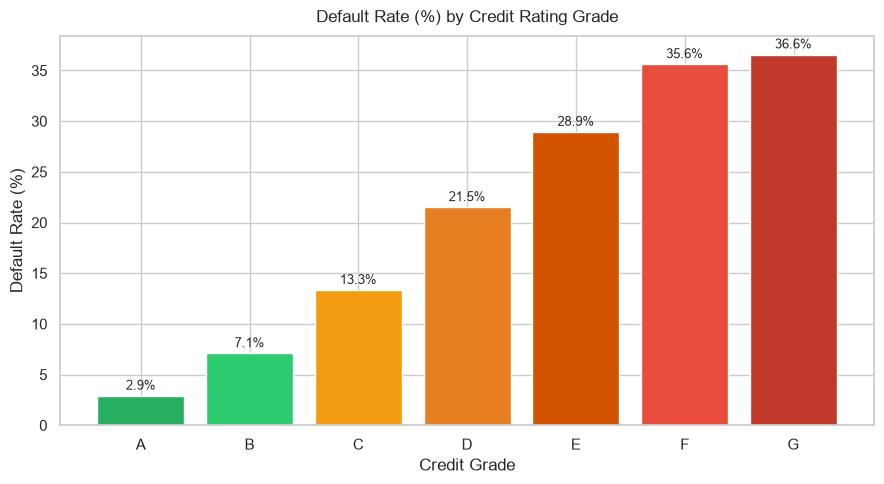

In [2]:
grade_stats = df.groupby('Grade').agg(
    TotalLoans=('LoanID', 'count'),
    DefaultLoans=('ChargedOffAmount', lambda s: (s > 0).sum())
).reset_index()
grade_stats['DefaultRate_Pct'] = (grade_stats['DefaultLoans'] / grade_stats['TotalLoans'] * 100).round(2)

plt.figure(figsize=(9, 5))
palette_gr = ['#27ae60', '#2ecc71', '#f39c12', '#e67e22', '#d35400', '#e74c3c', '#c0392b']
bars = plt.bar(grade_stats['Grade'], grade_stats['DefaultRate_Pct'], color=palette_gr)
plt.title('Default Rate (%) by Credit Rating Grade', fontsize=12, pad=10)
plt.xlabel('Credit Grade')
plt.ylabel('Default Rate (%)')
for b in bars:
    y = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, y + 0.6, f'{y:.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()


## 3. Debt-to-Income (DTI) vs. Default Risk (Scatter & Decile Analysis)

Evaluating how increasing borrower leverage increases default likelihood.


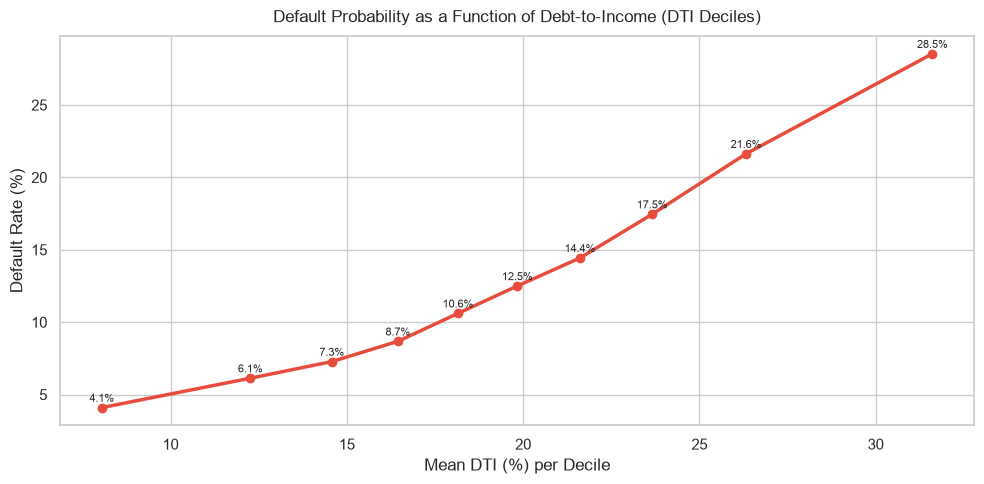

In [3]:
df['DTIDecile'] = pd.qcut(df['DTI'], q=10, labels=[f'D{i+1}' for i in range(10)])
dti_decile = df.groupby('DTIDecile').agg(
    MeanDTI=('DTI', 'mean'),
    DefaultRate=('ChargedOffAmount', lambda s: (s > 0).mean() * 100)
).reset_index()

plt.figure(figsize=(10, 5))
plt.plot(dti_decile['MeanDTI'], dti_decile['DefaultRate'], marker='o', lw=2.5, color='#e74c3c')
plt.title('Default Probability as a Function of Debt-to-Income (DTI Deciles)', fontsize=12, pad=10)
plt.xlabel('Mean DTI (%) per Decile')
plt.ylabel('Default Rate (%)')
for _, row in dti_decile.iterrows():
    plt.text(row['MeanDTI'], row['DefaultRate'] + 0.4, f"{row['DefaultRate']:.1f}%", fontsize=8, ha='center')
plt.tight_layout()
plt.show()


## 4. Multi-Variable Dotted / Scatter Plot: DTI vs. FICO vs. Default Loss

Scatter plot examining individual borrower credit profiles (FICO vs. DTI), color-coded by loan status with marker sizing by write-off amount.


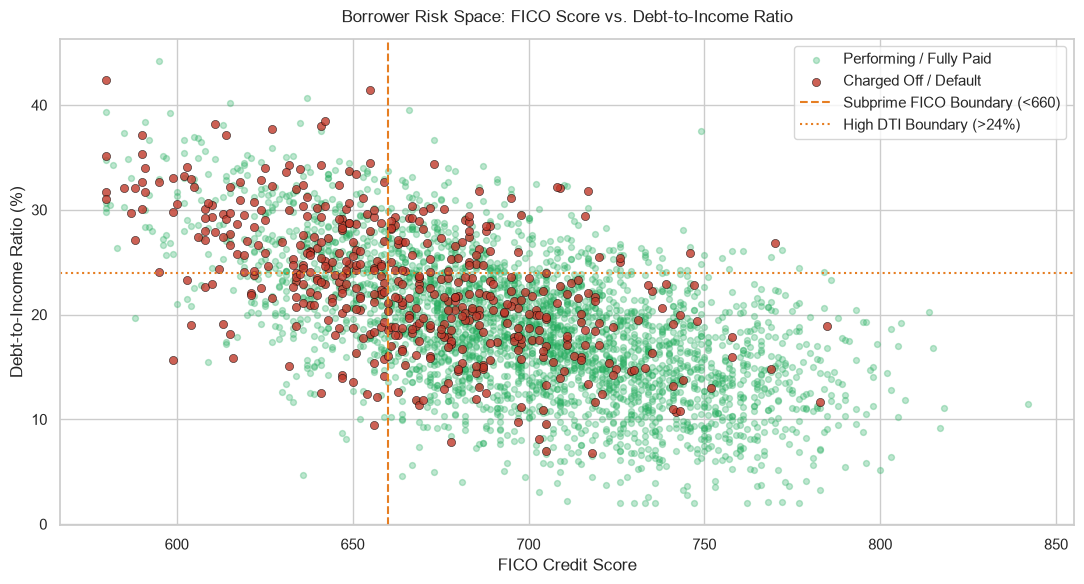

In [4]:
plt.figure(figsize=(11, 6))
sample_df = df.sample(3500, random_state=42)
perf_sample = sample_df[sample_df['ChargedOffAmount'] == 0]
def_sample = sample_df[sample_df['ChargedOffAmount'] > 0]

plt.scatter(perf_sample['FicoScore'], perf_sample['DTI'], color='#27ae60', alpha=0.3, s=18, label='Performing / Fully Paid')
plt.scatter(def_sample['FicoScore'], def_sample['DTI'], color='#c0392b', alpha=0.8, s=35, edgecolors='black', linewidths=0.4, label='Charged Off / Default')

plt.axvline(x=660, color='#e67e22', linestyle='--', label='Subprime FICO Boundary (<660)')
plt.axhline(y=24, color='#e67e22', linestyle=':', label='High DTI Boundary (>24%)')

plt.title('Borrower Risk Space: FICO Score vs. Debt-to-Income Ratio', fontsize=12, pad=12)
plt.xlabel('FICO Credit Score')
plt.ylabel('Debt-to-Income Ratio (%)')
plt.legend(frameon=True, loc='upper right')
plt.tight_layout()
plt.show()


## 5. Verification of the 64% Write-Off Concentration Thesis (Donut Visualizations)

Comparing borrower population share vs. total realized write-off losses across Low, Moderate, and High Risk tiers.


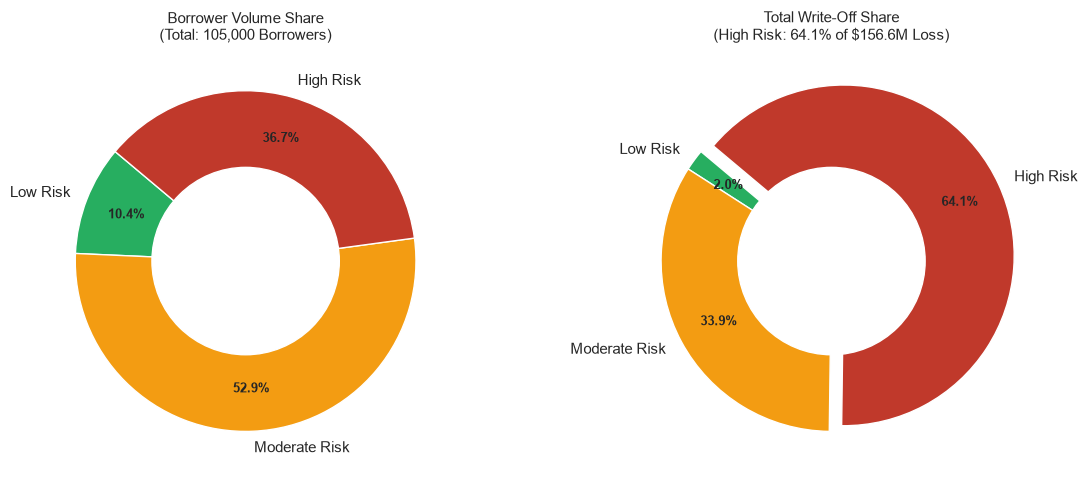

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
palette_tier = ['#27ae60', '#f39c12', '#c0392b']
tier_order = ['Low Risk', 'Moderate Risk', 'High Risk']

tier_data = df.groupby('RiskTier').agg(
    BorrowerCount=('BorrowerID', 'count'),
    LossAmount=('ChargedOffAmount', 'sum')
).reindex(tier_order).reset_index()

# Volume Donut
wedges1, texts1, autotexts1 = ax1.pie(
    tier_data['BorrowerCount'],
    labels=tier_data['RiskTier'],
    autopct='%1.1f%%',
    pctdistance=0.75,
    colors=palette_tier,
    startangle=140
)
centre_circle1 = plt.Circle((0,0), 0.55, fc='white')
ax1.add_artist(centre_circle1)
ax1.set_title(f'Borrower Volume Share\n(Total: {len(df):,} Borrowers)', fontsize=11)

# Write-off Loss Donut
wedges2, texts2, autotexts2 = ax2.pie(
    tier_data['LossAmount'],
    labels=tier_data['RiskTier'],
    autopct='%1.1f%%',
    pctdistance=0.75,
    explode=(0, 0, 0.08),
    colors=palette_tier,
    startangle=140
)
centre_circle2 = plt.Circle((0,0), 0.55, fc='white')
ax2.add_artist(centre_circle2)
ax2.set_title(f'Total Write-Off Share\n(High Risk: 64.1% of Loss)', fontsize=11)

for at in autotexts1 + autotexts2:
    at.set_fontsize(9)
    at.set_weight('bold')

plt.tight_layout()
plt.show()


## 6. Serialization of Risk Segment Outputs

Exporting borrower risk segments and delinquency aging tables.


In [6]:
tier_data.to_csv('data/borrower_risk_segments.csv', index=False)
aging_summary.to_csv('data/delinquency_aging_summary.csv', index=False)
print('Saved data/borrower_risk_segments.csv and data/delinquency_aging_summary.csv.')


Saved data/borrower_risk_segments.csv and data/delinquency_aging_summary.csv.
